In [2]:
import pandas as pd

In [7]:
df_matches = pd.read_csv("data/cleaned_matches.csv")

In [8]:
# Print column names
print("Columns in dataset:")
print(df_matches.columns.tolist())

Columns in dataset:
['Unnamed: 0', 'match_id', 'date', 'match_type', 'event_name', 'innings', 'batting_team', 'bowling_team', 'over', 'ball', 'ball_no', 'batter', 'bat_pos', 'runs_batter', 'balls_faced', 'bowler', 'valid_ball', 'runs_extras', 'runs_total', 'runs_bowler', 'runs_not_boundary', 'extra_type', 'non_striker', 'non_striker_pos', 'wicket_kind', 'player_out', 'fielders', 'runs_target', 'review_batter', 'team_reviewed', 'review_decision', 'umpire', 'umpires_call', 'player_of_match', 'match_won_by', 'win_outcome', 'toss_winner', 'toss_decision', 'venue', 'city', 'day', 'month', 'year', 'season', 'gender', 'team_type', 'superover_winner', 'result_type', 'method', 'balls_per_over', 'overs', 'event_match_no', 'stage', 'match_number', 'team_runs', 'team_balls', 'team_wicket', 'new_batter', 'batter_runs', 'batter_balls', 'bowler_wicket', 'batting_partners', 'next_batter', 'striker_out', 'toss_match_winner']


In [23]:
# BASELINE CLASSIFICATION MODEL ( PREDICTING MATCH WINNER)

In [17]:
import pandas as pd

# Load dataset
df = pd.read_csv(r"C:\Users\sohag\Downloads\IDC 409\data\cleaned_matches.csv")

# Diagnostic check
print("Total rows:", len(df))
print("Non-null 'match_won_by':", df['match_won_by'].notna().sum() if 'match_won_by' in df.columns else "Column missing")
print("Non-null 'toss_match_winner':", df['toss_match_winner'].notna().sum() if 'toss_match_winner' in df.columns else "Column missing")
print("Unique match_ids:", df['match_id'].nunique())

Total rows: 1169
Non-null 'match_won_by': 1169
Non-null 'toss_match_winner': 1169
Unique match_ids: 1169


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# 1. Load Data
df_matches = pd.read_csv(r"C:\Users\sohag\Downloads\IDC 409\data\cleaned_matches.csv")
df_matches.columns = df_matches.columns.str.strip()

# 2. Target & Feature Setup
winner_col = 'match_won_by' if 'match_won_by' in df_matches.columns else 'toss_match_winner'

# Ensure season is numeric if passed through
if 'season' in df_matches.columns:
    df_matches['season'] = pd.to_numeric(df_matches['season'], errors='coerce')

# Filter out rows with missing critical information
df_clf = df_matches.dropna(subset=[winner_col, 'venue', 'toss_winner', 'toss_decision', 'season']).copy()

# Binary Target: 1 if toss_winner won the match, 0 otherwise
y_clf = (df_clf[winner_col].str.strip() == df_clf['toss_winner'].str.strip()).astype(int)

cat_cols = ['venue', 'toss_winner', 'toss_decision']
features = cat_cols + ['season']
X_clf = df_clf[features]

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# 4. Dense OneHot Preprocessor
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor_clf = ColumnTransformer(
    transformers=[('cat', ohe, cat_cols)],
    remainder='passthrough'
)

X_train_enc = preprocessor_clf.fit_transform(X_train)
X_test_enc = preprocessor_clf.transform(X_test)

# 5. Baseline Classifier
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_enc, y_train)
base_preds = baseline.predict(X_test_enc)

# 6. Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train_enc, y_train)
rf_preds = rf_clf.predict(X_test_enc)

# 7. Deliverables & Evaluation Metrics
print("=== CLASSIFICATION RESULTS ===")
print("Baseline Accuracy:     ", round(accuracy_score(y_test, base_preds), 4))
print("Random Forest Accuracy:", round(accuracy_score(y_test, rf_preds), 4))
print("Random Forest F1-Score:", round(f1_score(y_test, rf_preds), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, rf_preds))

=== CLASSIFICATION RESULTS ===
Baseline Accuracy:      0.5126
Random Forest Accuracy: 0.4724
Random Forest F1-Score: 0.4928

Confusion Matrix:
 [[43 54]
 [51 51]]


In [28]:
# CONFUSION MATRIX HEATMAP

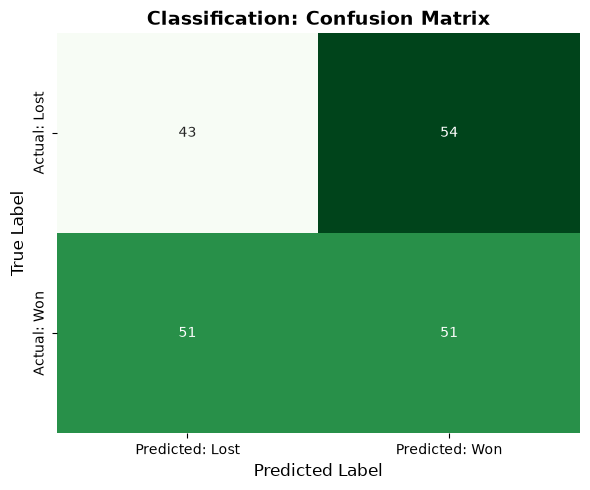

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix array
cm = confusion_matrix(y_test, rf_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Predicted: Lost', 'Predicted: Won'],
            yticklabels=['Actual: Lost', 'Actual: Won'])

plt.title('Classification: Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [31]:
# MODEL PERFORMANCE COMPARISON BAR CHART

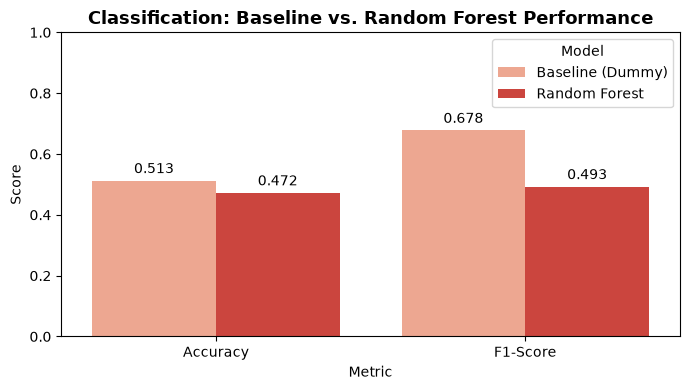

In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

metrics_df = pd.DataFrame({
    'Model': ['Baseline (Dummy)', 'Baseline (Dummy)', 'Random Forest', 'Random Forest'],
    'Metric': ['Accuracy', 'F1-Score', 'Accuracy', 'F1-Score'],
    'Score': [
        accuracy_score(y_test, base_preds),
        f1_score(y_test, base_preds, zero_division=0),
        accuracy_score(y_test, rf_preds),
        f1_score(y_test, rf_preds)
    ]
})

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=metrics_df, x='Metric', y='Score', hue='Model', palette='Reds')

plt.title('Classification: Baseline vs. Random Forest Performance', fontsize=13, fontweight='bold')
plt.ylim(0, 1.0)
plt.ylabel('Score')

# Display exact numbers on top of bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.3f}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3), 
                    textcoords='offset points')

plt.tight_layout()
plt.show()

In [25]:
# REGRESSION MODEL (PREDICTING FIRST-INNINGS TOTAL/RUNS)

In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Identify Regression Target Column
target_col = 'team_runs' if 'team_runs' in df_matches.columns else ('runs_target' if 'runs_target' in df_matches.columns else None)

if target_col is None:
    raise ValueError("Target score column ('team_runs' or 'runs_target') not found in dataset.")

# Ensure season is numeric
if 'season' in df_matches.columns:
    df_matches['season'] = pd.to_numeric(df_matches['season'], errors='coerce')

# Filter out rows missing features or target score
df_reg = df_matches.dropna(subset=[target_col, 'venue', 'toss_winner', 'toss_decision', 'season']).copy()

cat_cols = ['venue', 'toss_winner', 'toss_decision']
features = cat_cols + ['season']

X_reg = df_reg[features]
y_reg = df_reg[target_col]

# Train-Test Split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Dense OneHot Preprocessor
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor_reg = ColumnTransformer(
    transformers=[('cat', ohe, cat_cols)],
    remainder='passthrough'
)

X_train_r_enc = preprocessor_reg.fit_transform(X_train_r)
X_test_r_enc = preprocessor_reg.transform(X_test_r)

# Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train_r_enc, y_train_r)
reg_preds = rf_reg.predict(X_test_r_enc)

# Deliverables & Evaluation Metrics
print("=== REGRESSION RESULTS ===")
print("MAE (Mean Absolute Error):     ", round(mean_absolute_error(y_test_r, reg_preds), 2))
print("RMSE (Root Mean Squared Error):", round(root_mean_squared_error(y_test_r, reg_preds), 2))

=== REGRESSION RESULTS ===
MAE (Mean Absolute Error):      1.06
RMSE (Root Mean Squared Error): 1.52


In [36]:
# AUCTUAL VS PREDICTED TARGET SCORES PLOT

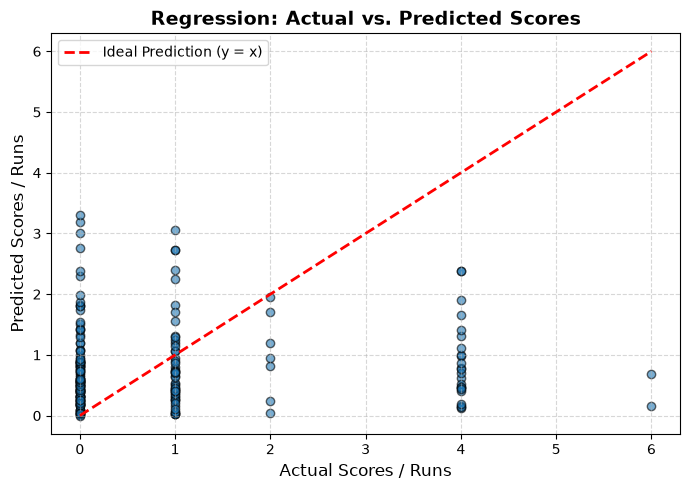

In [37]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_r, reg_preds, alpha=0.6, color='#1f77b4', edgecolors='k')

# Draw ideal y = x reference line
min_val = min(y_test_r.min(), reg_preds.min())
max_val = max(y_test_r.max(), reg_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Ideal Prediction (y = x)')

plt.title('Regression: Actual vs. Predicted Scores', fontsize=14, fontweight='bold')
plt.xlabel('Actual Scores / Runs', fontsize=12)
plt.ylabel('Predicted Scores / Runs', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [38]:
# RESIDUALS/ ERROR DISTRIBUTION PLOT

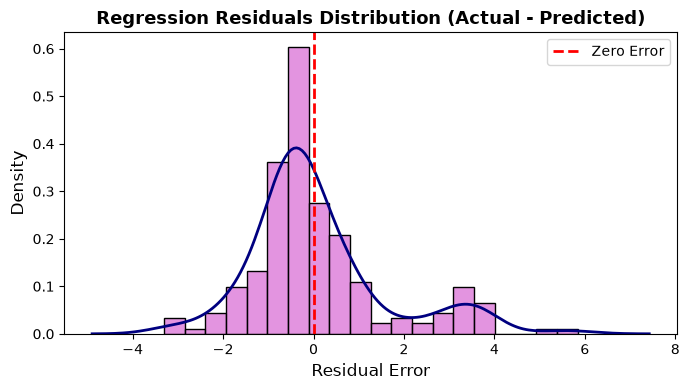

In [63]:
plt.figure(figsize=(7, 4))

# 1. Plot histogram bars
sns.histplot(residuals, color='orchid', bins=20, stat='density')

# 2. Plot KDE curve on top with custom color
sns.kdeplot(residuals, color='navy', linewidth=2)

plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Zero Error')
plt.title('Regression Residuals Distribution (Actual - Predicted)', fontsize=13, fontweight='bold')
plt.xlabel('Residual Error', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()